# Pair 1: SDXL and Kandinsky evaluation

This notebook checks the saved experiments and compares their results.
Upload "pair1_both_models_backup.zip".

In [1]:
from google.colab import files
from pathlib import Path
import zipfile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

uploaded = files.upload()

zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload one experiment ZIP."

project = Path("/content/pair1_evaluation")
project.mkdir(exist_ok=True)

# Restore the experiment
with zipfile.ZipFile(zip_names[0]) as archive:
    for name in archive.namelist():
        target = (project / name).resolve()
        assert target.is_relative_to(project.resolve()), "Invalid ZIP path."
    archive.extractall(project)

evaluation = project / "evaluation"
evaluation.mkdir(exist_ok=True)

print("Experiment restored.")

Saving pair1_both_models_backup.zip to pair1_both_models_backup.zip
Experiment restored.


## Check completed runs

Each model should have ten products and two seeds.
Saved images and masks are checked before comparing results.

In [2]:
# Completed comparison batches
sdxl_id = "20261101_014905"
kandinsky_id = "20261101_023309"

sdxl = pd.read_csv(
    project / "results" / f"sdxl_metrics_{sdxl_id}.csv"
)
kandinsky = pd.read_csv(
    project / "results" / f"kandinsky_metrics_{kandinsky_id}.csv"
)

config = json.loads(
    (project / "results" / f"sdxl_config_{sdxl_id}.json").read_text()
)

products = config["products"]
seeds = config["seeds"]
expected = {(product, seed) for product in products for seed in seeds}

for model, table in [("SDXL", sdxl), ("Kandinsky", kandinsky)]:
    assert not table.duplicated(["product", "seed"]).any(), \
        f"{model}: duplicate runs."

    actual = set(zip(table["product"], table["seed"]))
    assert actual == expected, f"{model}: missing or unexpected runs."

    for row in table.itertuples(index=False):
        with Image.open(project / row.output) as image:
            assert image.size == (768, 768), f"Wrong size: {row.output}"

    print(f"{model}: {len(table)} outputs checked.")

for product in products:
    with Image.open(project / "inputs" / f"{product}.png") as image:
        assert image.size == (768, 768)

    with Image.open(project / "masks" / f"{product}_mask.png") as image:
        mask = np.asarray(image.convert("L"))

    assert mask.shape == (768, 768)
    assert set(np.unique(mask)) == {0, 255}, f"Invalid mask: {product}"

print("All inputs, masks and output files passed.")

SDXL: 20 outputs checked.
Kandinsky: 20 outputs checked.
All inputs, masks and output files passed.


## Image-change measurements

MAE calculates the average of the absolute differences in pixel values on a scale from 0 to 255.
A lower protected-region MAE indicates that there are fewer modifications inside the protected mask.
The protected area has a small border around the product.
MAE evaluates changes, not the quality of the background or how well the prompt is followed.

In [3]:
checks = []

for model, table in [("SDXL", sdxl), ("Kandinsky", kandinsky)]:
    for row in table.itertuples(index=False):
        with Image.open(
            project / "inputs" / f"{row.product}.png"
        ) as image:
            before = np.asarray(image.convert("RGB"), dtype=np.float32)

        with Image.open(project / row.output) as image:
            after = np.asarray(image.convert("RGB"), dtype=np.float32)

        with Image.open(
            project / "masks" / f"{row.product}_mask.png"
        ) as image:
            protected = np.asarray(image.convert("L")) == 0

        difference = np.abs(after - before)
        protected_mae = float(difference[protected].mean())
        background_mae = float(difference[~protected].mean())

        assert np.isclose(protected_mae, row.protected_mae, atol=0.001)
        assert np.isclose(background_mae, row.background_mae, atol=0.001)

        checks.append({
            "model": model,
            "product": row.product,
            "seed": row.seed,
            "protected_mae": protected_mae,
            "background_mae": background_mae,
        })

verified = pd.DataFrame(checks)
verified.to_csv(evaluation / "verified_metrics.csv", index=False)

print(f"Verified measurements for {len(verified)} outputs.")

Verified measurements for 40 outputs.


## Compare time and memory



In [4]:
prior = json.loads(
    (project / "results" / "kandinsky_prior.json").read_text()
)

prior_time = sum(run["seconds"] for run in prior["runs"])
prior_peak = max(run["peak_allocated_gpu_gb"] for run in prior["runs"])

kandinsky_batch_seconds = (
    kandinsky["decoder_seconds"].sum() + prior_time
)

summary = pd.DataFrame([
    {
        "model": "SDXL",
        "outputs": len(sdxl),
        "mean_protected_mae": sdxl["protected_mae"].mean(),
        "mean_inference_seconds": sdxl["seconds"].mean(),
        "prior_seconds_shared": 0.0,
        "mean_seconds_with_shared_prior": sdxl["seconds"].mean(),
        "peak_allocated_gpu_gib": sdxl["peak_allocated_gpu_gb"].max(),
    },
    {
        "model": "Kandinsky",
        "outputs": len(kandinsky),
        "mean_protected_mae": kandinsky["protected_mae"].mean(),
        "mean_inference_seconds": kandinsky["decoder_seconds"].mean(),
        "prior_seconds_shared": prior_time,
        "mean_seconds_with_shared_prior":
            kandinsky_batch_seconds / len(kandinsky),
        "peak_allocated_gpu_gib": max(
            prior_peak,
            kandinsky["decoder_peak_allocated_gpu_gb"].max(),
        ),
    },
])

summary.to_csv(evaluation / "comparison_summary.csv", index=False)
display(summary.round(3))

,model,outputs,mean_protected_mae,mean_inference_seconds,prior_seconds_shared,mean_seconds_with_shared_prior,peak_allocated_gpu_gib
0,SDXL,20,27.752,18.856,0.00,18.856,5.230
1,Kandinsky,20,28.933,12.642,10.23,13.154,3.235


## Visual evaluation

The input and both outputs are reviewed for each product and seed.
Checks cover branding and shape preservation, the requested background,
unwanted objects and overall usability.

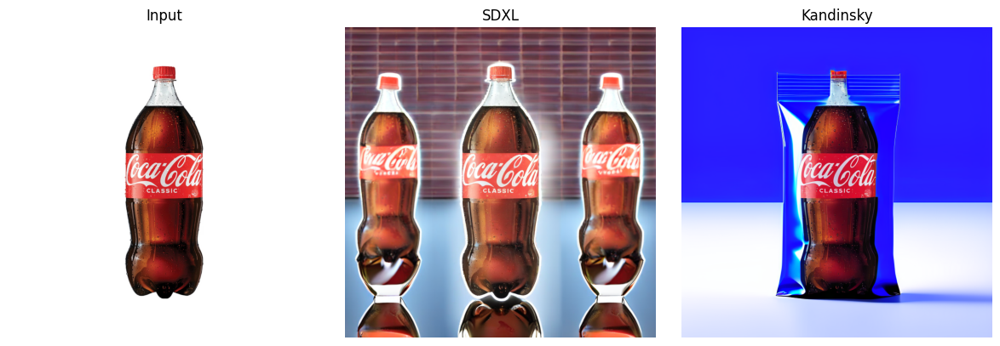

In [7]:
def show_case(product, seed):
    paths = [project / "inputs" / f"{product}.png"]

    for table in [sdxl, kandinsky]:
        row = table[
            (table["product"] == product) & (table["seed"] == seed)
        ].iloc[0]
        paths.append(project / row["output"])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    for ax, path, title in zip(
        axes, paths, ["Input", "SDXL", "Kandinsky"]
    ):
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_case("Coca_Cola", 42)

In [10]:
product = "Coca_Cola"
seed = 42

ratings = [
    {
        "model": "SDXL",
        "preservation": 3,
        "background": 1,
        "cleanliness": 1,
        "usable": "no",
        "notes": (
            "The central bottle remains recognisable, but its appearance "
            "changes. Extra bottles and reflections are generated. "
            "The background does not match the requested blue studio scene."
        ),
    },
    {
        "model": "Kandinsky",
        "preservation": 2,
        "background": 3,
        "cleanliness": 1,
        "usable": "no",
        "notes": (
            "The bottle remains recognisable, but an invented snack-style "
            "wrapper surrounds it. The background is blue, although the "
            "tabletop is very light and the backdrop is overly bright."
        ),
    },
]

# Check entries before saving
for rating in ratings:
    for field in ["preservation", "background", "cleanliness"]:
        assert rating[field] in [1, 2, 3, 4, 5], \
            f"Enter a score for {rating['model']}: {field}"
    assert rating["usable"] in ["yes", "no"], "Enter yes or no."
    assert rating["notes"].strip(), "Add a short observation."

review_file = evaluation / "visual_reviews.csv"

existing = (
    pd.read_csv(review_file)
    if review_file.exists()
    else pd.DataFrame(columns=["model", "product", "seed"])
)

# Keep reviews of other cases
existing = existing[
    ~((existing["product"] == product) & (existing["seed"] == seed))
]

new_rows = pd.DataFrame([
    dict(rating, product=product, seed=seed)
    for rating in ratings
])

saved = pd.concat([existing, new_rows], ignore_index=True)
saved.to_csv(review_file, index=False)

display(new_rows)
print("Saved. Total reviewed outputs:", len(saved))

,model,preservation,background,cleanliness,usable,notes,product,seed
0,SDXL,3,1,1,no,"The central bottle remains recognisable, but i...",Coca_Cola,42
1,Kandinsky,2,3,1,no,"The bottle remains recognisable, but an invent...",Coca_Cola,42


Saved. Total reviewed outputs: 2



Coca_Cola | seed 123


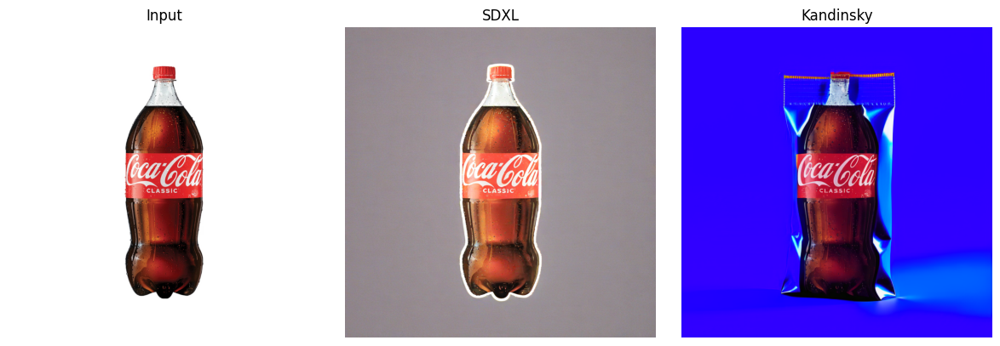


Coffee_cup | seed 42


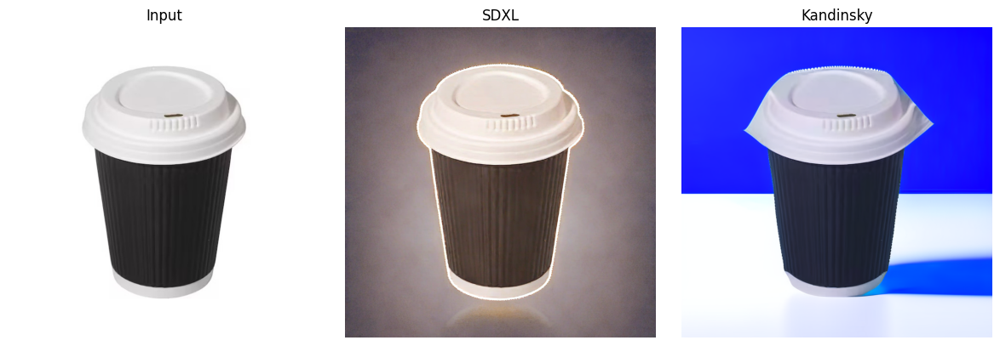


Coffee_cup | seed 123


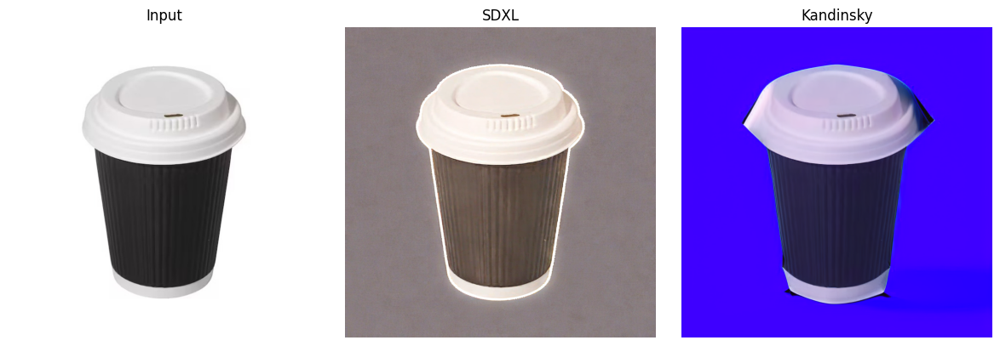


Doritos | seed 42


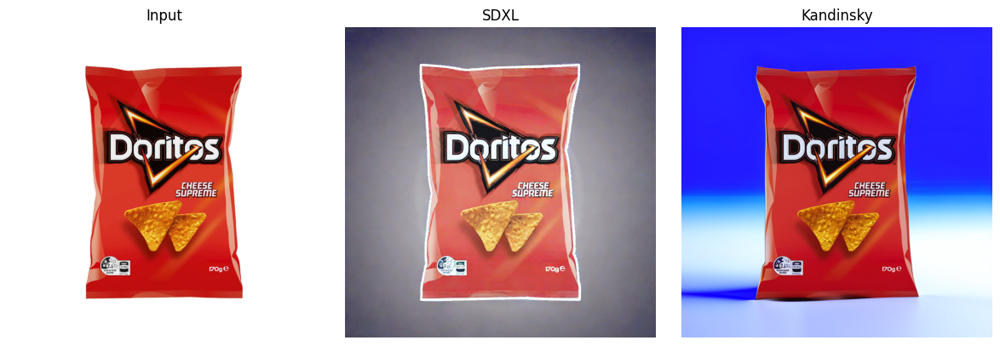


Doritos | seed 123


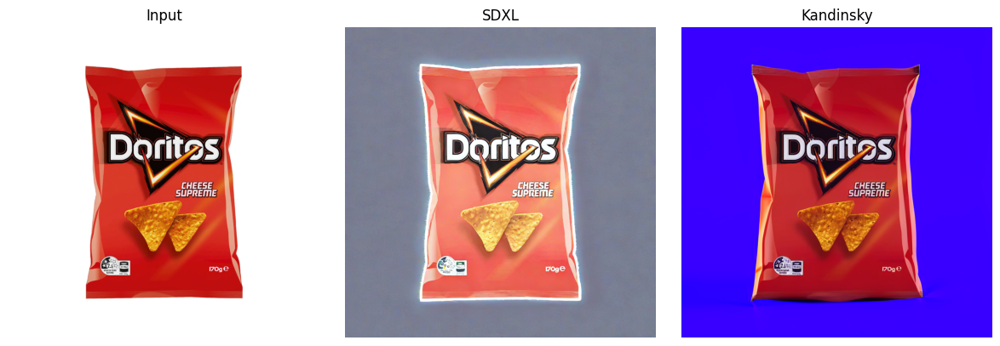


KitKat | seed 42


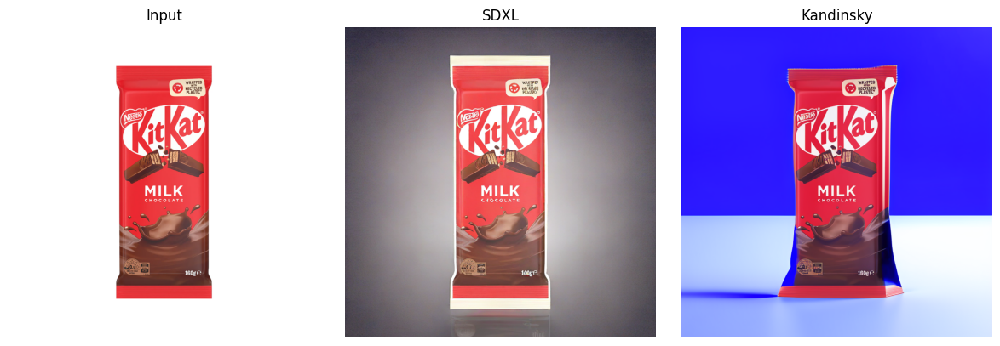


KitKat | seed 123


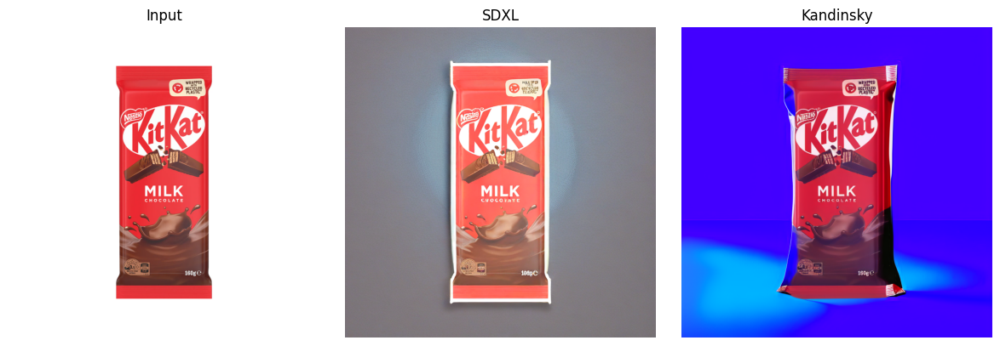


Mount_Franklin | seed 42


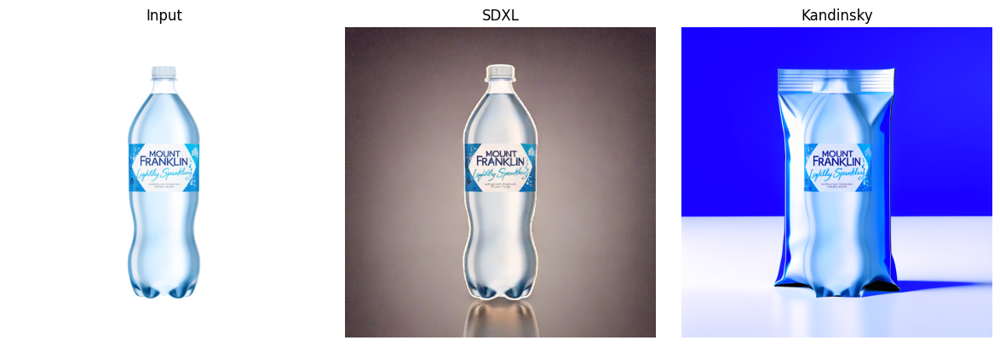


Mount_Franklin | seed 123


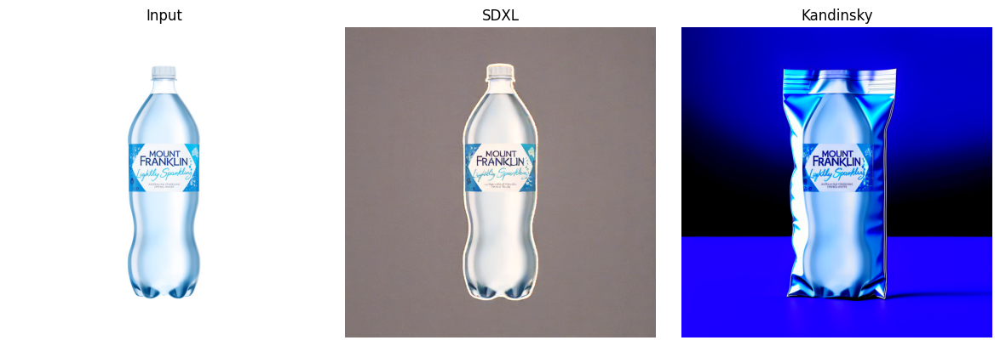


Oreo | seed 42


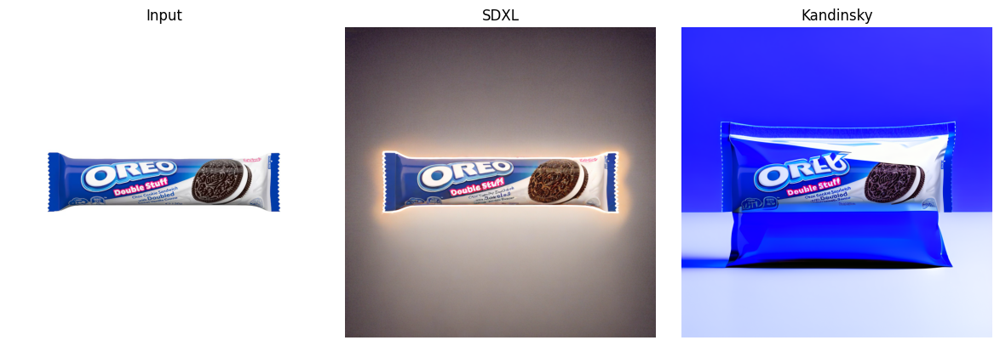


Oreo | seed 123


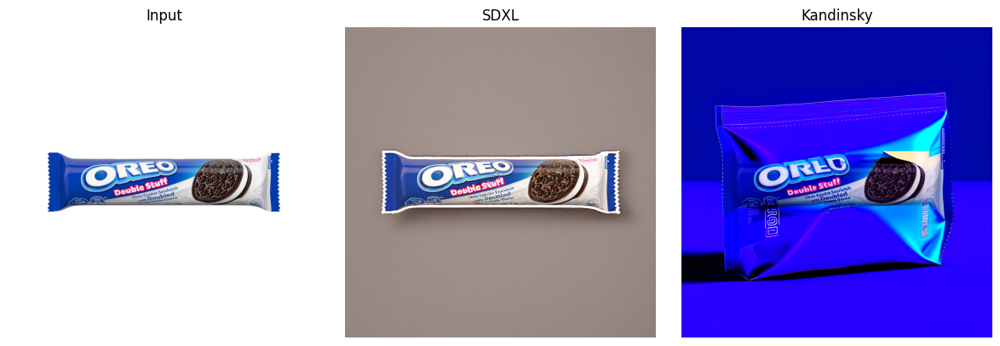


Pringles | seed 42


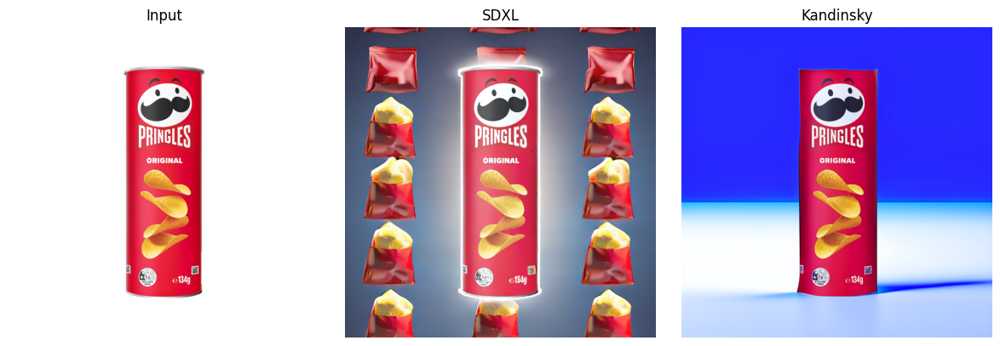


Pringles | seed 123


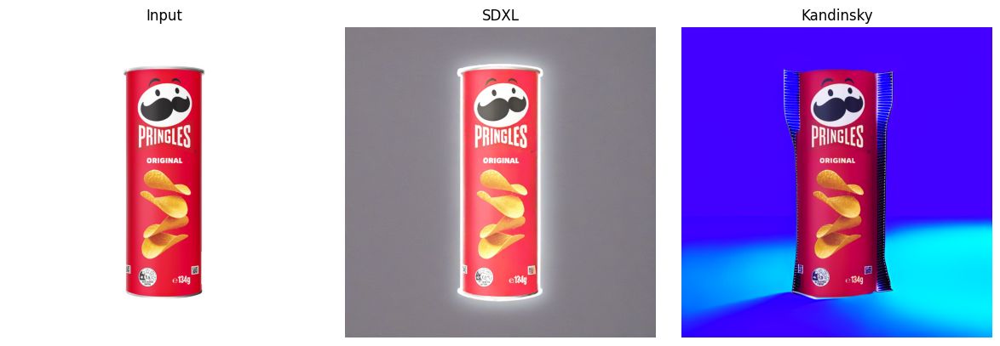


Red_Bull | seed 42


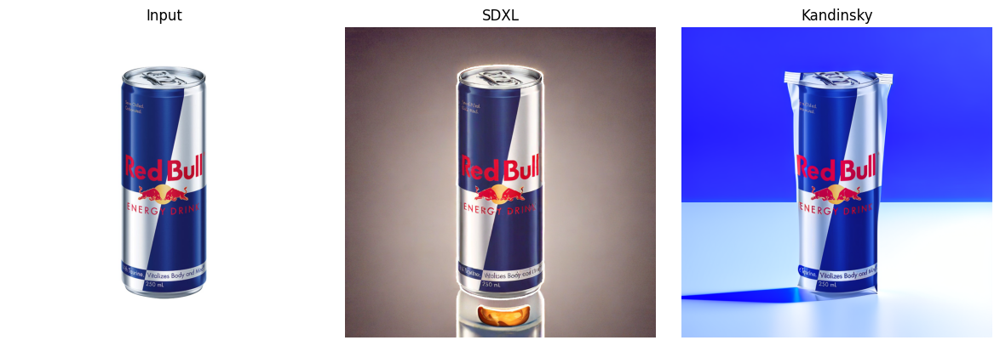


Red_Bull | seed 123


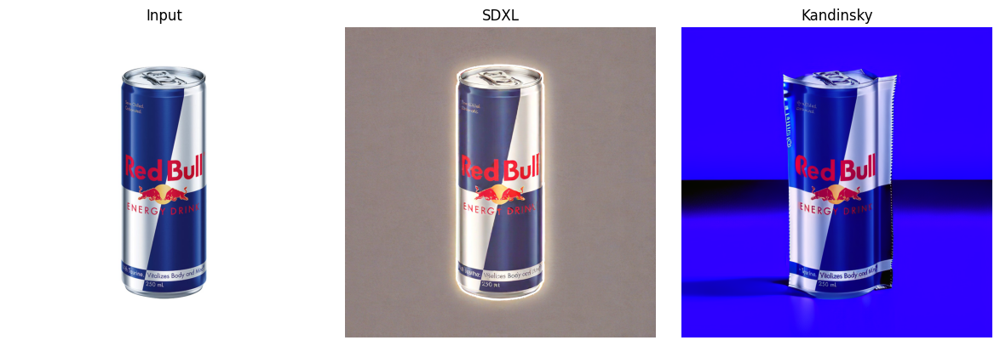


Red_Rock_Deli | seed 42


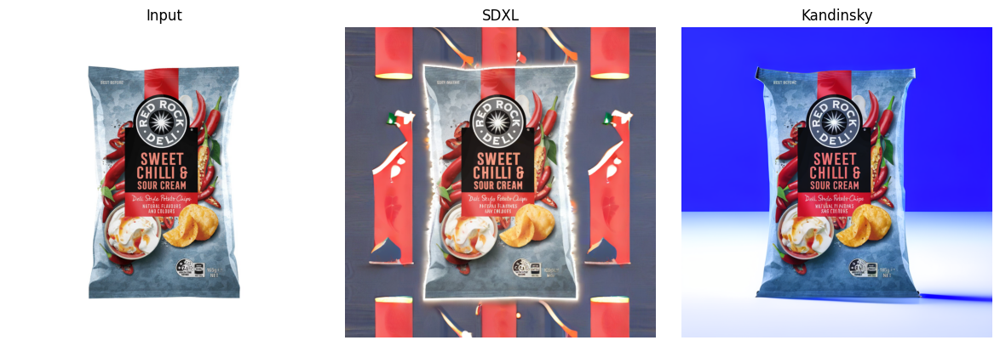


Red_Rock_Deli | seed 123


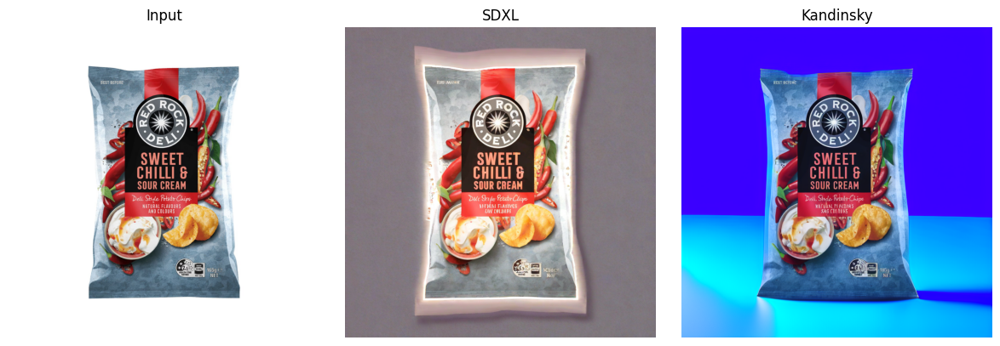


Smiths_Orginal | seed 42


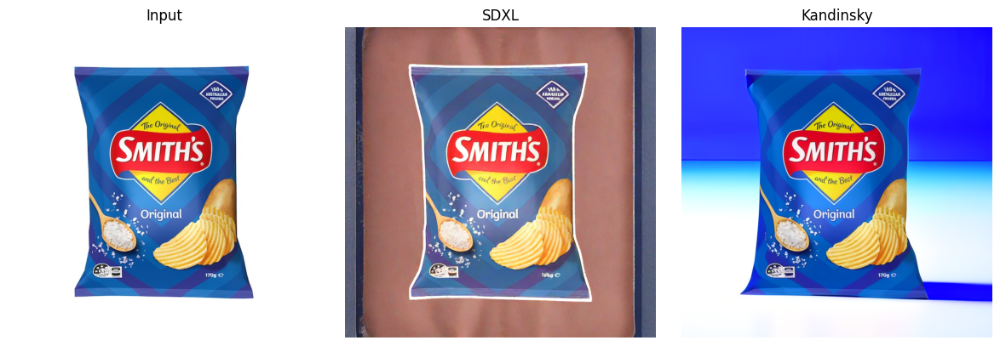


Smiths_Orginal | seed 123


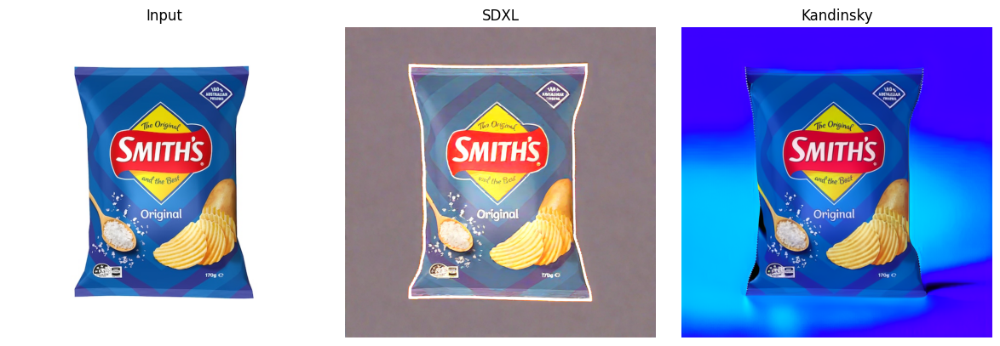

In [11]:
# Display all cases except the one already reviewed
for product in products:
    for seed in seeds:
        if product == "Coca_Cola" and seed == 42:
            continue

        print(f"\n{product} | seed {seed}")
        show_case(product, seed)

In [16]:
# Order: preservation, background, cleanliness, usable, notes

inspection = {
    ("Coca_Cola", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Bottle remains recognisable, but has a bright outline and a grey background instead of the requested blue scene."
        ],
        "Kandinsky": [
            2, 3, 1, "no",
            "An new wrapper surrounds the bottle.The background is blue but the product presentation changes."
        ],
    },
    ("Coffee_cup", 42): {
        "SDXL": [
            3, 1, 3, "no",
            "Cup remains recognisable, but its colour changes and a bright outline appears against a grey background."
        ],
        "Kandinsky": [
            3, 3, 2, "no",
            "Blue background is generated, but the lid gains an unnatural flared edge and a new tabletop like white surface."
        ],
    },
    ("Coffee_cup", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Cup and lid remain visible, but tones change and the background is grey rather than blue."
        ],
        "Kandinsky": [
            3, 3, 2, "no",
            "Blue scene partly matches the prompt, but the lid and lower cup edge appear altered."
        ],
    },
    ("Doritos", 42): {
        "SDXL": [
            3, 1, 3, "no",
            "Brand and packet remain recognisable, but colours are washed out and a white halo surrounds the packet."
        ],
        "Kandinsky": [
            4, 3, 4, "no",
            "Packet is mostly preserved with a blue studio background. The tabletop is pale and the backdrop is brighter than requested."
        ],
    },
    ("Doritos", 123): {
        "SDXL": [
            2, 1, 3, "no",
            "Packet colours and contrast change noticeably. A bright border remains against a grey background."
        ],
        "Kandinsky": [
            4, 3, 4, "no",
            "Packet remains recognisable with minor appearance changes. Blue background is present, but the tabletop is not clearly defined."
        ],
    },
    ("KitKat", 42): {
        "SDXL": [
            4, 1, 3, "no",
            "Main packaging layout is retained, but a pale outline appears and the background does not follow the blue prompt."
        ],
        "Kandinsky": [
            3, 3, 3, "no",
            "Brand remains recognisable, but the wrapper edges and bottom seal change against a bright blue scene."
        ],
    },
    ("KitKat", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Packaging remains recognisable, but its appearance changes and the background remains grey."
        ],
        "Kandinsky": [
            3, 3, 3, "no",
            "Wrapper shape and lower edge change. The blue scene only partly matches the requested studio setup."
        ],
    },
    ("Mount_Franklin", 42): {
        "SDXL": [
            4, 1, 3, "no",
            "Bottle shape and label are mostly retained, but lighting changes and the background is grey with a reflection."
        ],
        "Kandinsky": [
            1, 3, 1, "no",
            "The bottle is surrounded by invented metallic-looking packet packaging, substantially changing the product."
        ],
    },
    ("Mount_Franklin", 123): {
        "SDXL": [
            4, 1, 3, "no",
            "Bottle remains recognisable with changed tones and a bright edge against a grey background."
        ],
        "Kandinsky": [
            1, 2, 1, "no",
            "Bottle gains invented sealed-wrapper packaging. The background also contains a large dark area."
        ],
    },
    ("Oreo", 42): {
        "SDXL": [
            4, 1, 2, "no",
            "Main wrapper design is retained, but a strong glowing outline appears against the grey background."
        ],
        "Kandinsky": [
            2, 3, 1, "no",
            "The slim wrapper becomes a larger pouch-like package. Blue background is present but packaging is inaccurate."
        ],
    },
    ("Oreo", 123): {
        "SDXL": [
            4, 1, 3, "no",
            "Wrapper remains recognisable with a pale edge. The requested blue tabletop and backdrop are absent."
        ],
        "Kandinsky": [
            1, 3, 1, "no",
            "Wrapper shape, orientation and size change substantially into an invented pouch."
        ],
    },
    ("Pringles", 42): {
        "SDXL": [
            3, 1, 1, "no",
            "Central can remains recognisable, but many extra snack-like objects appear around it."
        ],
        "Kandinsky": [
            4, 3, 4, "no",
            "Can is mostly preserved without major extra objects.The pale tabletop and vivid backdrop only partly match the prompt."
        ],
    },
    ("Pringles", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Can remains recognisable, but colours change and a bright outline appears against a grey background."
        ],
        "Kandinsky": [
            3, 3, 4, "no",
            "Can remains recognisable, but lighting and colour change within a strongly coloured blue scene."
        ],
    },
    ("Red_Bull", 42): {
        "SDXL": [
            4, 1, 2, "no",
            "Can is mostly retained, but an extra object appears beneath it and the background is grey."
        ],
        "Kandinsky": [
            2, 3, 1, "no",
            "Invented wrapper-like edges surround the can, changing its packaging despite the blue background."
        ],
    },
    ("Red_Bull", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Can remains recognisable, but its tones change and a pale outline remains against a grey background."
        ],
        "Kandinsky": [
            2, 2, 1, "no",
            "Can gains distorted wrapper-like edges. A dark horizontal band interrupts the blue scene."
        ],
    },
    ("Red_Rock_Deli", 42): {
        "SDXL": [
            4, 1, 1, "no",
            "Main packet is retained, but extra packet fragments and repeated snack-like shapes appear around it."
        ],
        "Kandinsky": [
            4, 3, 4, "no",
            "Main packet design is mostly preserved with minor edge changes. The tabletop is lighter than requested."
        ],
    },
    ("Red_Rock_Deli", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Packet remains recognisable, but colours are washed out and a pale border appears against grey."
        ],
        "Kandinsky": [
            3, 3, 4, "no",
            "Packet remains recognisable, but its colour and edges change. The blue scene only partly follows the prompt."
        ],
    },
    ("Smiths_Orginal", 42): {
        "SDXL": [
            3, 1, 3, "no",
            "Packet remains recognisable, but colours change and the background is brown-grey with a bright border."
        ],
        "Kandinsky": [
            4, 3, 4, "no",
            "Packet design is mostly retained. The vivid blue background and pale tabletop partly match."
        ],
    },
    ("Smiths_Orginal", 123): {
        "SDXL": [
            3, 1, 3, "no",
            "Packet colours change and a white halo remains. The background does not match the blue studio instructions."
        ],
        "Kandinsky": [
            3, 3, 3, "no",
            "Packet remains recognisable, but its lower edge and lighting change against the blue scene."
        ],
    },
}

## Visual review summary

I checked all 40 outputs and given the ratings for product preservation, background adherence, cleanliness and usability.

In [19]:
review_file = evaluation / "visual_reviews.csv"
existing = pd.read_csv(review_file)

new_rows = []

for (product, seed), models in inspection.items():
    for model, values in models.items():
        preservation, background, cleanliness, usable, notes = values

        assert all(
            score in [1, 2, 3, 4, 5]
            for score in [preservation, background, cleanliness]
        ), f"Missing score: {model}, {product}, {seed}"

        assert usable in ["yes", "no"]
        assert notes.strip()

        new_rows.append({
            "model": model,
            "product": product,
            "seed": seed,
            "preservation": preservation,
            "background": background,
            "cleanliness": cleanliness,
            "usable": usable,
            "notes": notes,
        })

# Preserving the first two reviews and add the remaining cases
reviews = pd.concat(
    [existing, pd.DataFrame(new_rows)],
    ignore_index=True,
).drop_duplicates(["model", "product", "seed"], keep="last")

reviews.to_csv(review_file, index=False)

print("Saved reviews:", len(reviews))
display(reviews.groupby("model").size().rename("reviews"))

Saved reviews: 40


,reviews
model,
Kandinsky,20
SDXL,20


In [23]:
reviews = pd.read_csv(evaluation / "visual_reviews.csv")

# Check all expected reviews
expected_reviews = {
    (model, product, seed)
    for model in ["SDXL", "Kandinsky"]
    for product in products
    for seed in seeds
}

assert not reviews.duplicated(["model", "product", "seed"]).any()

actual_reviews = set(
    reviews[["model", "product", "seed"]].itertuples(
        index=False, name=None
    )
)

assert actual_reviews == expected_reviews, \
    "Some reviews are missing or unexpected."

score_columns = ["preservation", "background", "cleanliness"]

for column in score_columns:
    reviews[column] = pd.to_numeric(reviews[column], errors="raise")
    assert reviews[column].isin([1, 2, 3, 4, 5]).all()

reviews["usable"] = reviews["usable"].astype(str).str.strip().str.lower()
assert reviews["usable"].isin(["yes", "no"]).all()
assert reviews["notes"].fillna("").str.strip().ne("").all()

reviews["usable_flag"] = reviews["usable"].eq("yes")

visual_summary = reviews.groupby("model").agg(
    reviewed_outputs=("seed", "size"),
    mean_preservation=("preservation", "mean"),
    mean_background=("background", "mean"),
    mean_cleanliness=("cleanliness", "mean"),
    usable_outputs=("usable_flag", "sum"),
)

visual_summary["usable_percent"] = (
    100 * visual_summary["usable_outputs"]
    / visual_summary["reviewed_outputs"]
)

visual_summary.to_csv(evaluation / "visual_summary.csv")
display(visual_summary.round(2))

# Keep reviewer provenance
review_method = {
    "initial_ratings": "Visually checked draft",
    "student_review": "Student reports checking all output comparisons",
    "scale": "1 = very poor; 3 = partly meets; 5 = fully meets",
    "scope": "10 products, 2 seeds, 2 models, one shared prompt",
    "limitation": "Subjective review; no independent second human reviewer",
}

(evaluation / "review_method.json").write_text(
    json.dumps(review_method, indent=2)
)

print("All 40 reviews checked and summarised.")

,reviewed_outputs,mean_preservation,mean_background,mean_cleanliness,usable_outputs,usable_percent
model,,,,,,
Kandinsky,20,2.7,2.9,2.45,0,0.0
SDXL,20,3.3,1.0,2.60,0,0.0


All 40 reviews checked and summarised.


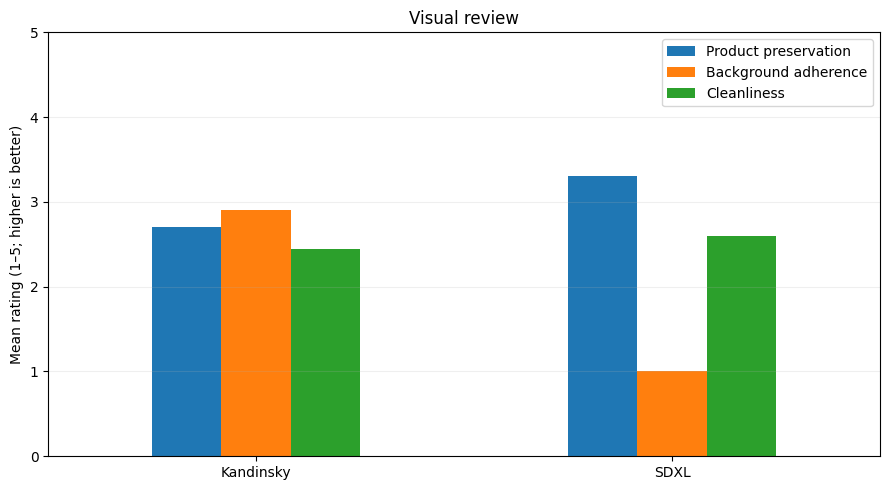

In [25]:
plot_data = visual_summary[
    ["mean_preservation", "mean_background", "mean_cleanliness"]
].copy()

plot_data.columns = [
    "Product preservation",
    "Background adherence",
    "Cleanliness",
]

ax = plot_data.plot.bar(
    figsize=(9, 5),
    ylim=(0, 5),
    rot=0,
)

ax.set_title("Visual review")
ax.set_xlabel("")
ax.set_ylabel("Mean rating (1–5; higher is better)")
ax.legend(title="")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    evaluation / "visual_ratings.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

In [22]:
import shutil

backup = shutil.make_archive(
    "/content/pair1_evaluated_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion and limitations

SDXL received better product-preservation ratings and slightly lower
protected-region MAE. Kandinsky followed the blue-background instruction
more closely and was faster when prior processing was shared across
the batch. Both produced visible defects.

No output was considered ready for use without needing editing during the review.
criteria. Neither of the tested workflows is recommended for creating things without someone watching or handling it.
of product advertisements.

These findings are for ten products, two seeds, and one prompt.
The phrase "snack packet" was not right for drinks and might have.
contributed to invented packaging. Visual ratings are subjective,
Pixel-change measurements alone do not prove that something can be used in a business setting.